# Shot Analysis

Reusable version of `first_shot.ipynb`: point `SHOT_FILE` at any shot CSV logged by the Pico (`shots/shot_NNN.csv`, columns `t,raw,voltage,bar`) and run all cells. The shot window is found automatically (first to last reading at or above `START_BAR`), so there's no hand-picked time range to update per shot.

Calibration: `bar = voltage / 3.3 * 16` (0V = 0 bar, the sensor's rated max 3.3V = 16 bar). Still the rough datasheet assumption, pending the side-by-side calibration against the analog gauge.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from shotlib import analyse, comparison_table, TARGET_BAR, THRESHOLD_BAR, START_BAR

SHOT_FILE = "data/shot_010.csv"
COMPARE_TO = "data/first_shot_2026-09-06.csv"

In [2]:
# analyse() lives in shotlib.py, shared with compare_shots.ipynb
df, m = analyse(SHOT_FILE)
df.head()

,t,t_log,raw,voltage,bar,phase
0,0.00,90.57,464,0.023,0.11,pre-infusion
1,0.18,90.75,706,0.036,0.17,pre-infusion
2,0.40,90.97,1076,0.054,0.26,pre-infusion
3,0.58,91.15,1345,0.068,0.33,pre-infusion
4,0.76,91.33,1545,0.078,0.38,pre-infusion


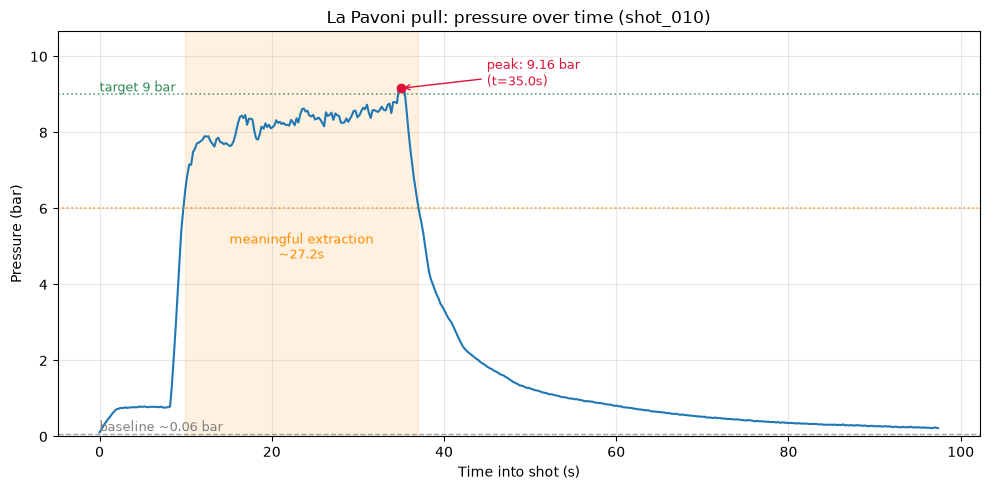

In [3]:
name = SHOT_FILE.split("/")[-1].removesuffix(".csv")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["t"], df["bar"], linewidth=1.5)

# baseline and target reference lines
ax.axhline(m["baseline_bar"], color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.text(df["t"].iloc[0], m["baseline_bar"], f"baseline ~{m['baseline_bar']:.2f} bar ",
        va="bottom", ha="left", color="gray", fontsize=9)
ax.axhline(TARGET_BAR, color="seagreen", linestyle=":", linewidth=1.2, alpha=0.8)
ax.text(df["t"].iloc[0], TARGET_BAR, f"target {TARGET_BAR:.0f} bar ",
        va="bottom", ha="left", color="seagreen", fontsize=9)

# meaningful-extraction threshold and shaded window
ax.axhline(THRESHOLD_BAR, color="darkorange", linestyle=":", linewidth=1.2, alpha=0.8)
ax.axvspan(m["extraction_start"], m["extraction_end"], color="darkorange", alpha=0.12)
ax.text((m["extraction_start"] + m["extraction_end"]) / 2, THRESHOLD_BAR - 0.6,
        f"meaningful extraction\n~{m['meaningful_s']:.1f}s", va="top", ha="center", color="darkorange", fontsize=9)

# peak
ax.plot(m["peak_t"], m["peak_bar"], "o", color="crimson")
ax.annotate(f"peak: {m['peak_bar']:.2f} bar\n(t={m['peak_t']:.1f}s)", xy=(m["peak_t"], m["peak_bar"]),
            xytext=(m["peak_t"] + 10, m["peak_bar"] + 0.4), va="center", fontsize=9, color="crimson",
            arrowprops=dict(arrowstyle="->", color="crimson"))

ax.set_xlabel("Time into shot (s)")
ax.set_ylabel("Pressure (bar)")
ax.set_title(f"La Pavoni pull: pressure over time ({name})")
ax.set_ylim(0, max(TARGET_BAR, df["bar"].max()) + 1.5)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f"figures/{name}.png", dpi=150)
plt.show()

In [4]:
shortfall = TARGET_BAR - m["peak_bar"]
status = "reached target" if shortfall <= 0 else f"fell short by {shortfall:.2f} bar"

print(f"Baseline (pre-shot) pressure: {m['baseline_bar']:.2f} bar")
print(f"Shot duration (>= {START_BAR} bar, same as the display timer): {m['shot_duration_s']:.1f}s")
print(f"Peak: {m['peak_bar']:.2f} bar at t={m['peak_t']:.1f}s ({status})")
print(f"Meaningful extraction time (>= {THRESHOLD_BAR} bar): {m['meaningful_s']:.1f}s")
print(f"Time at or above target (>= {TARGET_BAR} bar): {m['at_target_s']:.1f}s")

Baseline (pre-shot) pressure: 0.06 bar
Shot duration (>= 1.0 bar, same as the display timer): 46.4s
Peak: 9.16 bar at t=35.0s (reached target)
Meaningful extraction time (>= 6 bar): 27.2s
Time at or above target (>= 9 bar): 0.9s


## Area under the curve

Pressure integrated over time (bar*s), split into the highlighted >= 6 bar zone and everything else. Integrated above the resting baseline, so idle time before and after the shot contributes roughly nothing. A rough proxy for how much of the shot's total "pushing" happened at a meaningful pressure, rather than during pre-infusion and ramp-up or during the slow decay after the press.

before (pre-infusion, ramp-up)        11.5 bar*s     4%
highlighted zone (>= 6 bar)          219.5 bar*s    77%
after (decay)                         55.3 bar*s    19%
total                                286.4 bar*s

highlighted vs all other: 219.5 vs 66.8 bar*s (3.3x)


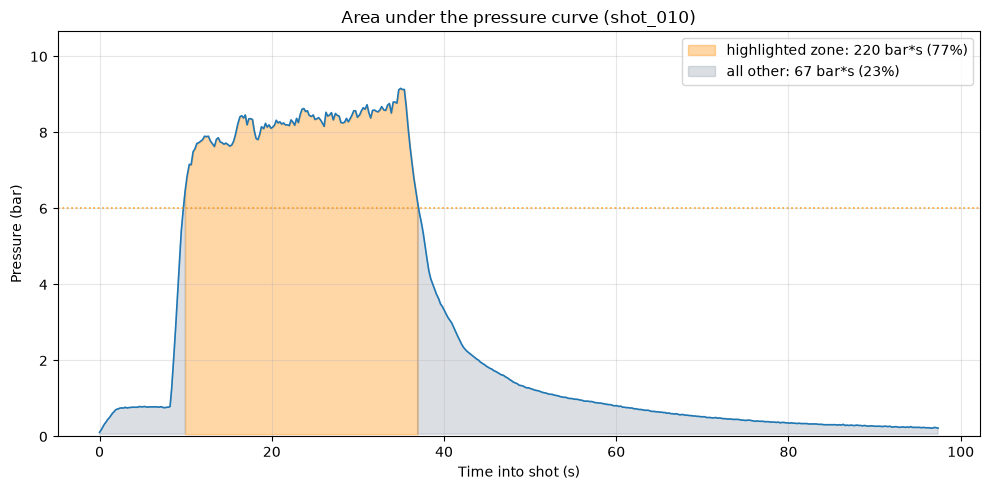

In [5]:
parts = {
    "before (pre-infusion, ramp-up)": m["area_before"],
    f"highlighted zone (>= {THRESHOLD_BAR} bar)": m["area_extraction"],
    "after (decay)": m["area_after"],
}
for label, a in parts.items():
    print(f"{label:34s} {a:7.1f} bar*s  {a / m['area_total']:5.0%}")
print(f"{'total':34s} {m['area_total']:7.1f} bar*s")
other = m["area_before"] + m["area_after"]
print(f"\nhighlighted vs all other: {m['area_extraction']:.1f} vs {other:.1f} bar*s "
      f"({m['area_extraction'] / other:.1f}x)")

# chart: the same curve, with the two areas filled in. Both fills include the
# zone's boundary samples, so there's no unshaded sliver where they meet.
excess_base = m["baseline_bar"]
in_zone = (df["t"] >= m["extraction_start"]) & (df["t"] <= m["extraction_end"])
outside = (df["t"] <= m["extraction_start"]) | (df["t"] >= m["extraction_end"])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["t"], df["bar"], color="tab:blue", linewidth=1.2)
ax.fill_between(df["t"], excess_base, df["bar"], where=in_zone, color="darkorange", alpha=0.35,
                label=f"highlighted zone: {m['area_extraction']:.0f} bar*s ({m['area_extraction'] / m['area_total']:.0%})")
ax.fill_between(df["t"], excess_base, df["bar"], where=outside, color="slategray", alpha=0.25,
                label=f"all other: {other:.0f} bar*s ({other / m['area_total']:.0%})")
ax.axhline(THRESHOLD_BAR, color="darkorange", linestyle=":", linewidth=1.2, alpha=0.8)
ax.set_xlabel("Time into shot (s)")
ax.set_ylabel("Pressure (bar)")
ax.set_title(f"Area under the pressure curve ({name})")
ax.set_ylim(0, max(TARGET_BAR, df["bar"].max()) + 1.5)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f"figures/{name}_area.png", dpi=150)
plt.show()

## Compared with the first shot

Both shots on the same "time into shot" axis. What's the same is as telling as what's different:

- **The press itself started the same way.** Pre-infusion sat at the same ~0.75-0.8 bar (boiler pressure), and the climb from 1 to 6 bar took 1.6 s both times.
- **The difference is entirely what happened after reaching 6 bar.** The first shot touched 7.4 bar and immediately collapsed: 2.7 s above 6 bar. shot_010 held about 8.2 bar on average for 27 s, ten times as long, before release.
- **Longer pre-infusion:** 8.4 s vs 5.5 s before pressing (timed from 0.1 bar, as on the Pico's screen).
- **Logging rate:** the first shot was logged every 0.55 s (the old logger), shot_010 every 0.21 s, so the first curve is coarser and its peak may be slightly under-reported.

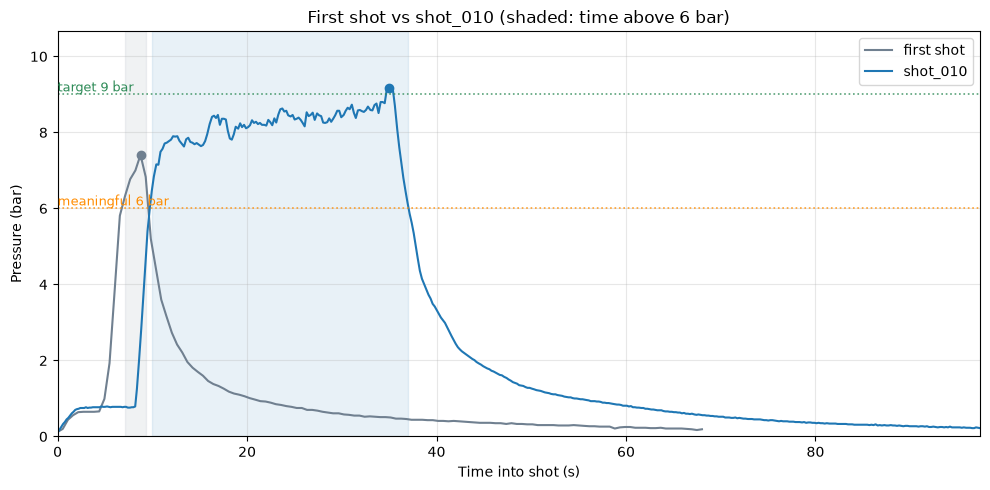

,first shot,shot_010
shot timer: pre-infusion + extraction (s),9.8,37.2
pre-infusion (s),5.5,8.4
pre-infusion pressure (bar),0.56,0.69
extraction (s),4.4,28.8
dripping (s),58.2,60.2
"ramp, 1 to 6 bar (s)",1.6,1.6
"meaningful extraction, >= 6 bar (s)",2.7,27.2
average pressure in that zone (bar),6.87,8.18
peak (bar),7.41,9.16
peak at (s into shot),8.8,35.0


In [6]:
first_df, first = analyse(COMPARE_TO)

# both curves on one "time into shot" axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(first_df["t"], first_df["bar"], color="slategray", linewidth=1.5, label="first shot")
ax.plot(df["t"], df["bar"], color="tab:blue", linewidth=1.5, label=name)
for d, r, colour in ((first_df, first, "slategray"), (df, m, "tab:blue")):
    ax.axvspan(r["extraction_start"], r["extraction_end"], color=colour, alpha=0.10)
    ax.plot(r["peak_t"], r["peak_bar"], "o", color=colour)
ax.axhline(TARGET_BAR, color="seagreen", linestyle=":", linewidth=1.2, alpha=0.8)
ax.text(0, TARGET_BAR, f"target {TARGET_BAR:.0f} bar ", va="bottom", ha="left", color="seagreen", fontsize=9)
ax.axhline(THRESHOLD_BAR, color="darkorange", linestyle=":", linewidth=1.2, alpha=0.8)
ax.text(0, THRESHOLD_BAR, f"meaningful {THRESHOLD_BAR:.0f} bar ", va="bottom", ha="left", color="darkorange", fontsize=9)
ax.set_xlabel("Time into shot (s)")
ax.set_ylabel("Pressure (bar)")
ax.set_title(f"First shot vs {name} (shaded: time above {THRESHOLD_BAR} bar)")
ax.set_xlim(0, max(first_df["t"].max(), df["t"].max()))
ax.set_ylim(0, max(TARGET_BAR, df["bar"].max(), first_df["bar"].max()) + 1.5)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f"figures/first_vs_{name}.png", dpi=150)
plt.show()

comparison_table({"first shot": first, name: m})

## Takeaway (shot_010)

**Verdict: a very good shot.** Balanced, with no sourness and no bitterness. Flavour notes were hard to pick out, but that's down to the beans (cheap, very dark roast from Lidl, fresh), not the extraction. Setup: 9 g in the small basket, grind setting 3. See `data/shot_notes.csv`.

That gives this project its first known-good profile to measure against:

- ~8 s pre-infusion at boiler pressure (~0.7 bar)
- a fast climb to ~8 bar (1 to 6 bar in 1.6 s)
- held at roughly 8 to 8.6 bar for ~27 s, 78% of the shot's pressure-time in the >= 6 bar zone
- a brief 9.16 bar spike at the end of the press, then release

Against the first shot (sour, 2.7 s above 6 bar), the same metric that explained the bad shot also lines up with the good one: meaningful extraction time went from 2.7 s to 27 s, and the taste went from sour to balanced. Two shots isn't proof, but it's the first pair of data points pointing the same way.

Worth noting: only ~0.9 s was spent at or above 9 bar, so a good shot here didn't need to sit at the textbook 9 bar. Dark roasts extract easily, which may be why ~8 bar was plenty. Whether a lighter roast needs more is a good question for a future shot.